# 逻辑回归

### 问题

线性回归输出的是任意实数,拿来做二分类没法直接用。逻辑回归在线性部分外面套一个 sigmoid,把结果压到 0 到 1 之间,当成概率:

$$p=\sigma(z)=\frac{1}{1+e^{-z}},\qquad z=w^Tx+b$$

损失用交叉熵,比 MSE 更适合分类:

$$L=-\frac{1}{n}\sum_{i=1}^{n}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$$

对 w 求导会得到一个很干净的形式:

$$\frac{\partial L}{\partial w}=\frac{1}{n}X^T(p-y)$$

没有线性回归那个系数 2,是因为交叉熵对 z 求导刚好等于 p - y,sigmoid 的导数被约掉了。

## 1. 造一份数据

两类点分别从 (2, 2) 和 (5, 5) 附近生成,各 100 个,两个方向都有重叠。

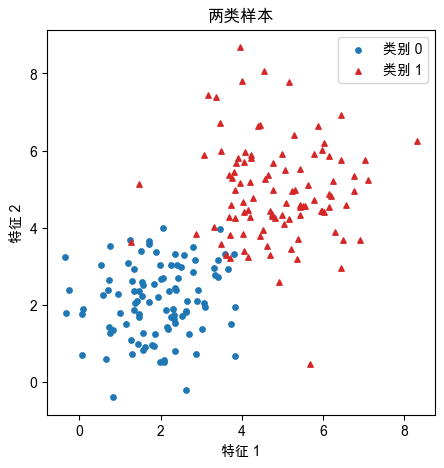

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

# 本机 numpy 2.0 会对 matmul 误报浮点警告,结果是对的
warnings.filterwarnings("ignore", message=".*in matmul")

# 中文和负号
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

rng = np.random.default_rng(0)
n = 100
X = np.r_[rng.normal([2, 2], 1.0, (n, 2)), rng.normal([5, 5], 1.2, (n, 2))]
y = np.r_[np.zeros(n), np.ones(n)]

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[y == 0, 0], X[y == 0, 1], s=15, label="类别 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=15, c="tab:red", marker="^", label="类别 1")
ax.set_xlabel("特征 1")
ax.set_ylabel("特征 2")
ax.set_title("两类样本")
ax.legend()
plt.show()

两个中心隔了 4 左右,但标准差也不小,交界处有一批点怎么画线都分不开。所以后面准确率大概到 97% 就到头了,不是没训练好。

## 2. 先手写一遍

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w = np.zeros(2)
b = 0.0
lr = 0.5

for _ in range(1000):
    p = sigmoid(X @ w + b)
    w -= lr * (X.T @ (p - y)) / len(y)
    b -= lr * (p - y).mean()

p = sigmoid(X @ w + b)
loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

print("w", np.round(w, 3), "b", round(b, 3))
print("loss", round(loss, 4), "accuracy", round(((p >= 0.5) == y).mean(), 4))

w [1.543 1.471] b -10.063
loss 0.1013 accuracy 0.97


迭代里只有三行:sigmoid 算概率,`p - y` 是误差,乘 X 求平均就是梯度。和线性回归比,这里换的只是把输出压到 0 到 1 的函数和损失函数,更新公式长得一模一样。

## 3. 封装成类

和上一个算法一样的套路:`fit` / `predict_proba` / `predict` / `score`,代码在 [logistic_regression.py](logistic_regression.py)。

In [3]:
from logistic_regression import LogisticRegression, sigmoid, bce

model = LogisticRegression(lr=0.5, n_iters=1000).fit(X, y)
print("和手写循环一致:", np.allclose(
    [model.coef_[0], model.coef_[1], model.intercept_], [w[0], w[1], b]))

model = LogisticRegression(lr=0.5, n_iters=20000).fit(X, y)
print("w", np.round(model.coef_, 3), "b", round(model.intercept_, 3))
print("loss", round(model.loss_history_[-1], 4), "accuracy", round(model.score(X, y), 4))

和手写循环一致: True


w [2.425 2.432] b -16.302
loss 0.0874 accuracy 0.97


多跑两万步,loss 从 0.10 降到 0.087,准确率没变。两类在交界处本来就有重叠,再往下压 loss 只是把边界附近那些点推来推去,分不动的还是分不动。

另外 w 的两个分量差不多相等,因为两类中心在 45 度方向上,分界线垂直于它。

## 4. 决策边界

把平面上每个点的概率都算出来,涂个色就能看到模型到底学了什么。

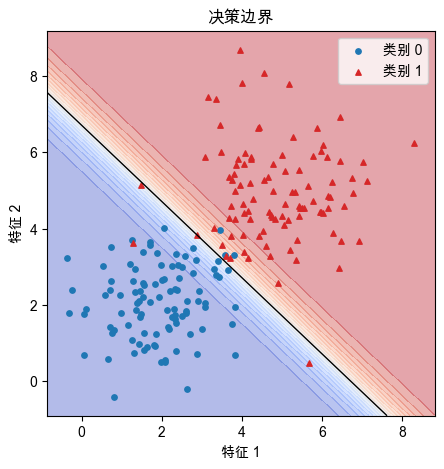

In [4]:
pad = 0.5
x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
proba = model.predict_proba(grid).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(5, 5))
ax.contourf(xx, yy, proba, levels=20, cmap="coolwarm", alpha=0.4)
ax.contour(xx, yy, proba, levels=[0.5], colors="black", linewidths=1)

ax.scatter(X[y == 0, 0], X[y == 0, 1], s=15, label="类别 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=15, c="tab:red", marker="^", label="类别 1")
ax.set_xlabel("特征 1")
ax.set_ylabel("特征 2")
ax.set_title("决策边界")
ax.legend()
plt.show()

概率从蓝到红是渐变的,但 0.5 的那条线还是直线,因为 z 对 x 是线性的。逻辑回归只能画直线边界,遇到月牙形数据就没辙了。

## 5. 学习率

和线性回归一样,lr 小走不动,lr 大容易来回跳。区别是逻辑回归的损失不会像 MSE 那样爆到 1e166,最坏也就是停在某个位置不降。

In [5]:
for lr in [0.01, 0.1, 0.5]:
    m = LogisticRegression(lr=lr, n_iters=1000).fit(X, y)
    print(f"lr={lr:<5} loss={m.loss_history_[-1]:.4f} acc={m.score(X, y):.3f}")

lr=0.01  loss=0.4229 acc=0.865
lr=0.1   loss=0.1600 acc=0.960
lr=0.5   loss=0.1013 acc=0.970


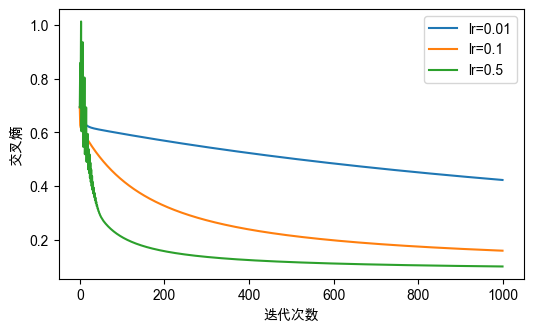

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))

for lr in [0.01, 0.1, 0.5]:
    m = LogisticRegression(lr=lr, n_iters=1000).fit(X, y)
    ax.plot(m.loss_history_, label=f"lr={lr}")

ax.set_xlabel("迭代次数")
ax.set_ylabel("交叉熵")
ax.legend()
plt.show()

lr=0.01 一千步才降到 0.42,lr=0.5 已经到 0.10。绿色那条前几步还在 0.69 和 1.01 之间来回蹦,蹦了几下才稳下来,lr 再往上就会一直蹦。这里 x 在 2 到 6 之间,0.5 还能站得住。

后面曲线都变得很平,是因为梯度里带着 `p - y`,当模型对大部分点已经很自信时,这个差接近 0,只能靠边界附近那些点推着走。

## 6. 真实数据:乳腺癌

sklearn 自带的二分类数据,569 条样本,30 个特征(细胞核的半径、纹理、面积等),标签 0 是恶性、1 是良性。

30 个特征量纲差很多,先标准化。

In [7]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

X_c, y_c = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X_c, y_c, test_size=0.2, random_state=0, stratify=y_c)

print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


In [8]:
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0)
X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

model = LogisticRegression(lr=0.5, n_iters=2000).fit(X_train_s, y_train)
print("train acc", round(model.score(X_train_s, y_train), 4))
print("test  acc", round(model.score(X_test_s, y_test), 4))

train acc 0.9912
test  acc 0.9825


[[40  2]
 [ 0 72]]


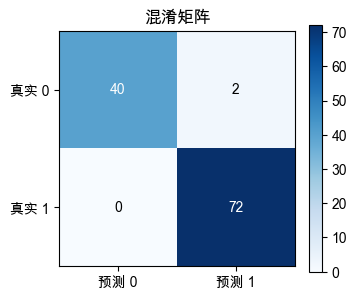

In [9]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, model.predict(X_test_s))
print(cm)

fig, ax = plt.subplots(figsize=(3.8, 3.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["预测 0", "预测 1"])
ax.set_yticklabels(["真实 0", "真实 1"])

for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")

fig.colorbar(im, ax=ax)
ax.set_title("混淆矩阵")
plt.show()

114 个测试样本里错了 2 个,都是恶性被判成良性。准确率 0.9825 看着好看,但这种错误在筛查里代价最大,所以真要用还得调阈值,或者看召回率。

拿 sklearn 的版本对一下。它默认用 lbfgs,迭代到完全收敛:

In [10]:
from sklearn.linear_model import LogisticRegression as SklearnLR

sk = SklearnLR(penalty=None, max_iter=5000).fit(X_train_s, y_train)
print("sklearn train", round(sk.score(X_train_s, y_train), 4))
print("sklearn test ", round(sk.score(X_test_s, y_test), 4))
print(confusion_matrix(y_test, sk.predict(X_test_s)))

sklearn train 1.0
sklearn test  0.9474
[[40  2]
 [ 4 68]]


同一个模型,sklearn 把训练集推到 100%,测试集反而掉到 0.947,把 4 个良性判成了恶性。我们只跑 2000 步就停,相当于早停,测试集 0.9825。

所以优化方式会直接影响泛化。同样的算法,迭代到收敛和提前停手,测试集差了 0.035。

## 7. 小结

- 逻辑回归就是线性模型加 sigmoid,输出可以当概率用,但只能画线性边界;
- 交叉熵的梯度是 (p - y),和线性回归的 (预测值 - 真实值) 形状一样,只是 p 被压到了 0 到 1;
- 数据不线性可分时,最优 loss 也不是 0,梯度下降后半程会走得很慢;
- 多特征一定要标准化,30 个特征量纲混在一起不标准化根本收敛不了;
- 早停会影响泛化,训练集 100% 不一定是好事。